# CS771 Mini-Project 1: Next-Day PM2.5 Forecasting (Bihar) and Heatmaps
**Parts 1–5.** Part 0 (Kanpur cleaning) is in `part0_kanpur_cleaning.ipynb`.

**Task:** at the issue time 12:00 IST on day *d*, forecast PM2.5 at all 468 stations for 12:00 on day *d+1*.

**Fixed protocol, used everywhere below:**
- **Split by target time:** train on targets 1 Jan – 31 Aug 2024, validate on targets 1 Sep – 30 Nov 2024
  (every station × every one of the 91 noon targets).
- **No leakage:** every feature uses readings at or before the issue time. Anything fitted (scalers, station means,
  PCA, k-means, models) is fitted on training rows only. No random shuffling.
- **Metrics:** RMSE and MAE in µg/m³ at stations, overall and per validation month.
- **Models:** only methods covered up to lecture 16 (linear/ridge/lasso, kNN, trees, forests, boosting,
  k-means, PCA). No neural networks, no external data. Fixed seeds.

Feature code lives in `features.py` (same folder) so that `forecast.py` (Part 5) builds exactly the same features.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import features as F

SEED = 0
np.random.seed(SEED)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 2)


def find_data_dir():
    """Locate the course data folder. Set the MP1_DATA environment variable to override."""
    cands = [os.environ.get("MP1_DATA", ""), "data", "../mp1-package/data",
             "../../Desktop/CS771/Miniproj1/mp1-package/data", "../data"]
    for c in cands:
        if c and (Path(c) / "bihar_pm25_hourly_jan_nov_2024.csv").exists():
            return Path(c)
    raise FileNotFoundError("Course data not found: set MP1_DATA to the mp1-package/data folder")


DATA = find_data_dir()
W = pd.read_csv(DATA / "bihar_pm25_hourly_jan_nov_2024.csv", index_col="timestamp", parse_dates=True)
W.columns = W.columns.astype(str)
stations = pd.read_csv(DATA / "bihar_stations.csv", dtype={"sensor_id": str}).set_index("sensor_id")
grid = pd.read_csv(DATA / "bihar_grid_005deg.csv")
boundary = pd.read_csv(DATA / "bihar_boundary.csv")
assert list(stations.index) == list(W.columns)

V = W.to_numpy(dtype=float)             # (8040 hours, 468 stations)
times = W.index
S = V.shape[1]
print(f"data: {DATA.resolve()}\n{V.shape[0]} hours x {S} stations, {times[0]} -> {times[-1]}")

data: C:\Users\HP\Desktop\CS771\Miniproj1\mp1-package\data
8040 hours x 468 stations, 2024-01-01 00:00:00 -> 2024-11-30 23:00:00


### Split and evaluation helpers
An example is indexed by its **issue row** `i` (a row of `V`). The target is row `i + lead`.
For the main task the lead is 24 h and the issue hour is 12:00.

In [2]:
TRAIN_END = pd.Timestamp("2024-08-31 23:59")
VAL_START, VAL_END = pd.Timestamp("2024-09-01"), pd.Timestamp("2024-11-30 23:59")


def issue_rows(lead=24, target_hour=12, min_history=24):
    """Issue rows for training and validation, split by TARGET time."""
    tgt = np.where(times.hour == target_hour)[0]
    tgt = tgt[tgt - lead - (min_history - 1) >= 0]                # enough history before the issue time
    tt = times[tgt]
    tr = tgt[tt <= TRAIN_END] - lead
    va = tgt[(tt >= VAL_START) & (tt <= VAL_END)] - lead
    return tr, va


def evaluate(pred, idx, lead=24, name="model"):
    """RMSE / MAE overall and per validation month. pred is issue-major (len(idx) * S,)."""
    y = F.targets(V, idx, lead)
    month = np.repeat(times[idx + lead].month, S)
    rows = {"overall": (pred, y)}
    for m in sorted(set(month)):
        rows[pd.Timestamp(2024, m, 1).strftime("%b")] = (pred[month == m], y[month == m])
    out = {}
    for k, (p, t) in rows.items():
        out[(k, "RMSE")] = np.sqrt(np.mean((p - t) ** 2))
        out[(k, "MAE")] = np.mean(np.abs(p - t))
    return pd.Series(out, name=name)


def persistence(idx):
    return V[idx].reshape(-1)


tr24, va24 = issue_rows()
print(f"validation: {len(va24)} targets ({times[va24[0] + 24]} ... {times[va24[-1] + 24]}), "
      f"{len(va24) * S} station-forecasts")

validation: 91 targets (2024-09-01 12:00:00 ... 2024-11-30 12:00:00), 42588 station-forecasts


---
## Part 1: Required baselines
1. **Persistence:** the forecast is the station's reading at the issue time.
2. **Ridge(alpha = 1.0)** on 29 raw, unscaled features:
   - the station's 24 hourly readings t, t−1 h, …, t−23 h;
   - the mean of its 10 nearest other stations (km distance) at t, and averaged over t−23 h … t;
   - the network mean at t;
   - sin and cos of 2πd/365, with d = days since 1 Jan 2024 of the issue day.

   The model pools all stations and every training target that has 24 h of history.
   Negative forecasts are clipped to 0.

In [3]:
M10 = F.knn_weights(F.distance_matrix(stations), k=10)


def fit_ridge29(tr_idx, lead=24):
    X, y = F.base29(V, tr_idx, times, M10), F.targets(V, tr_idx, lead)
    return Ridge(alpha=1.0).fit(X, y), len(y)


def predict_ridge29(model, idx):
    return np.clip(model.predict(F.base29(V, idx, times, M10)), 0, None)


ridge29, n_rows = fit_ridge29(tr24)
print(f"Ridge-29 trained on {n_rows} rows = {len(tr24)} training targets "
      f"({times[tr24[0] + 24].date()} ... {times[tr24[-1] + 24].date()}) x {S} stations")

P1 = pd.DataFrame([evaluate(persistence(va24), va24, name="Persistence"),
                   evaluate(predict_ridge29(ridge29, va24), va24, name="Ridge-29 (Part 1)")])
P1

Ridge-29 trained on 113256 rows = 242 training targets (2024-01-03 ... 2024-08-31) x 468 stations


overall           Sep           Oct           Nov       
                     RMSE    MAE   RMSE    MAE   RMSE    MAE   RMSE    MAE
Persistence         32.75  17.47  23.33   8.91  20.22  11.97  47.81  31.70
Ridge-29 (Part 1)   29.58  18.16  20.34  10.35  19.36  13.46  43.06  30.81

The first training target is 3 Jan: the 2 Jan 12:00 target would be issued on 1 Jan 12:00, which has only 13 hours of history.

**Q: Does one baseline win on both metrics? Why might a model trained on squared error lose on absolute error?**

No. Ridge has the **lower RMSE**, but persistence has the **lower MAE** (see the table above).
- Ridge minimises squared error. Squaring makes the rare large errors (pollution episodes, mostly in November)
  dominate the loss, so ridge learns to hedge: it pulls forecasts toward the conditional *mean*, shrinking
  extremes and partly regressing to the network level.
- That hedging lowers the big errors that RMSE punishes. But on the many ordinary days it adds a small error
  that persistence doesn't have, because persistence is often almost exact when the air is stable.
  MAE weights all errors linearly, so these many small errors add up.
- The squared-loss optimum is the conditional mean; the absolute-loss optimum is the conditional *median*.
  PM2.5 is right-skewed, so the mean sits above the median, which makes a mean-seeking model systematically
  too high on typical days.

In [4]:
P1_PRED = {"Persistence": persistence(va24), "Ridge-29": predict_ridge29(ridge29, va24)}
y_va = F.targets(V, va24)
pd.DataFrame({k: {"mean error (bias)": np.mean(p - y_va), "median error": np.median(p - y_va),
                  "share of |error| < 5 µg/m³": np.mean(np.abs(p - y_va) < 5)} for k, p in P1_PRED.items()}).T

,mean error (bias),median error,share of |error| < 5 µg/m³
Persistence,-0.47,-0.75,0.33
Ridge-29,5.32,7.20,0.22


This supports the explanation: ridge's *median* error is clearly positive (too high on a typical day), and it is
within 5 µg/m³ far less often than persistence.

---
## Part 2: Improving the forecast
### Feature groups
Eight groups, each built from one idea (code in `features.py`):

| group | idea | features |
|---|---|---|
| `recent` | the station's last 24 hourly readings (as in Part 1) | 24 |
| `neighbours` | 10-NN mean now and over 24 h; mean of stations within 25 km and 50 km now; 50 km mean over 24 h | 5 |
| `network` | network mean now, over 24 h and over 72 h; first 5 **PCA** components of the (log) network snapshot at t (PCA fitted on training issue times, L15) | 8 |
| `history` | same hour (12:00) on each of the previous 7 days; daily means of the previous 6 days; 7-day mean | 14 |
| `trend` | today's 24 h mean − yesterday's; value now − 24 h ago; now − 3 h ago; now − today's mean | 4 |
| `calendar` | sin/cos of day of year; sin/cos of the **target's** day of week | 4 |
| `station` | station's long-run training mean and std; its 7-day level relative to the network; x, y (km); one-hot **k-means** cluster of station locations (k = 6, L14) | 11 |
| `anomaly` | how far the station sits above/below its surroundings: now − 10-NN mean, now − 25 km mean, now − 50 km mean, now − network mean, 24 h mean − 10-NN 24 h mean, and (now anomaly − 24 h anomaly). These 6 are strongly correlated, so they are standardised and compressed by **PCA to 2 components** (fitted on training rows) | 2 |

The `anomaly` group was *found*, not guessed: see "Finding new features" below.

The longest lookback is 7 days + 23 h, so the first usable training target is 10 Jan (7 fewer days than Part 1).
Station means/std, PCA and k-means are fitted on training data only (readings up to the last training target,
31 Aug 12:00), then frozen.

**Target:** most models predict the **change** y(t+24 h) − y(t) and add it back to the current reading.
This keeps every model anchored to persistence and helps tree models a lot (trees cannot extrapolate
beyond the levels they saw in training, but changes are on a similar scale across seasons).

In [5]:
LOOKBACK = F.MAX_LOOKBACK_H
TRAIN_STATS_END = np.searchsorted(times, pd.Timestamp("2024-08-31 12:00")) + 1   # rows up to the last training target


def part2_rows(tr_idx):
    return tr_idx[tr_idx - LOOKBACK >= 0]


tr2 = part2_rows(tr24)
fb = F.FeatureBuilder(stations, seed=SEED).fit(V[:TRAIN_STATS_END], tr2)
Xtr, feat_names = fb.transform(V, tr2, times)
Xva, _ = fb.transform(V, va24, times)
ytr, yva = F.targets(V, tr2), F.targets(V, va24)
now_tr, now_va = V[tr2].reshape(-1), V[va24].reshape(-1)
slices = fb.group_slices(V, tr2, times)
print(f"Part 2 training rows: {len(ytr)} = {len(tr2)} targets ({times[tr2[0] + 24].date()} ... "
      f"{times[tr2[-1] + 24].date()}) x {S} stations; {Xtr.shape[1]} features")
pd.DataFrame({"n_features": {g: b - a for g, (a, b) in slices.items()}})

c:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Part 2 training rows: 109980 = 235 targets (2024-01-10 ... 2024-08-31) x 468 stations; 72 features


,n_features
recent,24
neighbours,5
network,8
history,14
trend,4
calendar,4
station,11
anomaly,2


### Finding new features: importance screening on training data only
14 candidate features were built (below), each a new idea not in the first 7 groups. To rank them **without
touching validation**, the boosted-tree model is trained on Jan–Jun targets and the candidates are ranked by
**permutation importance** on the held-out Jul–Aug *training* targets: how much RMSE rises when that feature's
values are shuffled (an importance measure in the same spirit as SHAP, built into scikit-learn).

One candidate dominates: **the station's reading minus its 10 neighbours' mean** (`own_minus_nn`). Physically, a
local excess above the neighbourhood tends to fade by the next day. Related "station vs surroundings" features
were then built into the `anomaly` group. Because they are highly correlated, they are compressed with PCA.

In [6]:
def _wmean(idx, a, b):          # mean over lags a..b hours (inclusive), per station
    return np.mean(np.stack([V[idx - l] for l in range(a, b + 1)], 0), 0)


def candidate_features(idx):
    now, M10_ = V[idx], fb.M10
    night, eve = _wmean(idx, 6, 12), _wmean(idx, 13, 18)          # 00-06 today, 18-23 yesterday
    m24, m24y = _wmean(idx, 0, 23), _wmean(idx, 24, 47)
    last24 = np.stack([V[idx - l] for l in range(24)], 0)
    net = lambda A: np.repeat(A.mean(1, keepdims=True), S, 1)
    f = {"night_mean": night, "evening_mean_yday": eve, "night_minus_now": night - now,
         "evening_minus_now": eve - now, "std_24h": last24.std(0), "max_24h": last24.max(0),
         "mean3d_minus_prev3d": _wmean(idx, 0, 71) - _wmean(idx, 72, 143),
         "nn_trend_24h": now @ M10_.T - V[idx - 24] @ M10_.T, "own_minus_nn": now - now @ M10_.T,
         "net_trend_24h": net(now) - net(V[idx - 24]), "net_day_trend": net(m24) - net(m24y),
         "net_night_mean": net(night), "net_night_minus_now": net(night) - net(now), "net_evening_yday": net(eve)}
    return np.stack(list(f.values()), -1).reshape(len(idx) * S, -1), list(f)


from sklearn.inspection import permutation_importance
C_tr, cand_names = candidate_features(tr2)
base_cols = np.concatenate([np.arange(*slices[g]) for g in slices if g != "anomaly"])
A_tr = np.c_[Xtr[:, base_cols], C_tr]
inner_fit = np.repeat(np.asarray(times[tr2 + 24] <= pd.Timestamp("2024-06-30 23:59")), S)   # Jan-Jun vs Jul-Aug
h_inner = HistGradientBoostingRegressor(learning_rate=0.03, max_iter=150, max_depth=4, min_samples_leaf=200,
                                        l2_regularization=1.0, random_state=SEED).fit(A_tr[inner_fit],
                                                                                      (ytr - now_tr)[inner_fit])
sub = np.random.RandomState(SEED).choice(np.where(~inner_fit)[0], 20000, replace=False)
pi = permutation_importance(h_inner, A_tr[sub], (ytr - now_tr)[sub], n_repeats=3, random_state=SEED,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean[-len(cand_names):], index=cand_names, name="RMSE increase when shuffled")
imp.sort_values(ascending=False).round(3)

own_minus_nn           2.09e-01
net_night_mean         6.10e-02
evening_minus_now      1.30e-02
std_24h                5.00e-03
mean3d_minus_prev3d    5.00e-03
max_24h                3.00e-03
nn_trend_24h           0.00e+00
night_mean             0.00e+00
evening_mean_yday      0.00e+00
net_evening_yday       0.00e+00
net_night_minus_now   -0.00e+00
night_minus_now       -0.00e+00
net_day_trend         -0.00e+00
net_trend_24h         -4.00e-03
Name: RMSE increase when shuffled, dtype: float64

In [7]:
raw_anom = fb._anomaly_raw(V, tr2).reshape(-1, len(F.ANOMALY_NAMES))
print("correlation between the 6 raw anomaly features (training rows):")
print(pd.DataFrame(np.corrcoef(raw_anom.T), index=F.ANOMALY_NAMES, columns=F.ANOMALY_NAMES).round(2).to_string())
print(f"\nPCA keeps 2 components = {fb.anom_explained_:.1%} of their variance")

correlation between the 6 raw anomaly features (training rows):
                            own_minus_nn10  own_minus_r25  own_minus_r50  own_minus_net  mean24_minus_nn10_mean24  now_anom_minus_mean24_anom
own_minus_nn10                        1.00           0.97           0.96           0.86                      0.70                        0.36
own_minus_r25                         0.97           1.00           0.95           0.85                      0.68                        0.35
own_minus_r50                         0.96           0.95           1.00           0.91                      0.67                        0.35
own_minus_net                         0.86           0.85           0.91           1.00                      0.60                        0.31
mean24_minus_nn10_mean24              0.70           0.68           0.67           0.60                      1.00                       -0.41
now_anom_minus_mean24_anom            0.36           0.35           0.35           0

### Model comparison (all choices made on validation)
Every model gets the same 72 features (all 8 groups). "level" means predicting y directly; "change" means predicting y − y(t).
Train RMSE is shown to diagnose overfitting. Hyperparameters were picked on validation with small grids
(the ridge grid is shown below).

In [8]:
RIDGE_ALPHA = 100                     # placeholder; replaced by the validation-chosen value below
HGB_PARAMS = dict(learning_rate=0.03, max_iter=150, max_depth=4, min_samples_leaf=200, l2_regularization=1.0,
                  random_state=SEED)


def make_model(kind):
    if kind == "ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
    if kind == "lasso":
        return make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=5000))
    if kind == "knn":
        return make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=100, weights="distance", n_jobs=-1))
    if kind == "rf":
        return RandomForestRegressor(n_estimators=100, min_samples_leaf=50, max_features=0.33, n_jobs=-1,
                                     random_state=SEED)
    if kind == "hgb":
        return HistGradientBoostingRegressor(**HGB_PARAMS)
    if kind == "hgb_deep":
        return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, min_samples_leaf=50, random_state=SEED)
    raise ValueError(kind)


def rmse(p, y):
    return float(np.sqrt(np.mean((p - y) ** 2)))


alpha_grid = {}
for a in [1, 10, 100, 1000, 10000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xtr, ytr - now_tr)
    alpha_grid[a] = rmse(np.clip(m.predict(Xva) + now_va, 0, None), yva)
print("ridge alpha -> validation RMSE:", {k: round(v, 2) for k, v in alpha_grid.items()})
RIDGE_ALPHA = min(alpha_grid, key=alpha_grid.get)            # chosen on validation
print("chosen alpha:", RIDGE_ALPHA)

ridge alpha -> validation RMSE: {1: 29.02, 10: 29.02, 100: 29.0, 1000: 28.94, 10000: 28.94}
chosen alpha: 1000


In [9]:
candidates = [  # (label, model kind, target)
    ("Ridge, level", "ridge", "level"),
    ("Ridge, change", "ridge", "change"),
    ("Lasso, change", "lasso", "change"),
    ("kNN (k=100, distance-weighted), change", "knn", "change"),
    ("Boosted trees, deep, level", "hgb_deep", "level"),
    ("Boosted trees, shallow, change", "hgb", "change"),
    ("Random forest, change", "rf", "change"),
]
fitted, val_pred, rows = {}, {}, []
for label, kind, target in candidates:
    t0 = time.time()
    off_tr, off_va = (now_tr, now_va) if target == "change" else (0.0, 0.0)
    m = make_model(kind).fit(Xtr, ytr - off_tr)
    p_va = np.clip(m.predict(Xva) + off_va, 0, None)
    tr_rmse = np.nan if kind == "knn" else rmse(np.clip(m.predict(Xtr) + off_tr, 0, None), ytr)   # kNN memorises
    fitted[label], val_pred[label] = m, p_va
    rows.append({"model": label, "train RMSE": tr_rmse, "val RMSE": rmse(p_va, yva),
                 "val MAE": np.mean(np.abs(p_va - yva)), "fit+predict s": time.time() - t0})
    print(f"{label:42s} val RMSE {rows[-1]['val RMSE']:.2f}  ({rows[-1]['fit+predict s']:.0f} s)")

# Average of the two complementary "change" models (a simple ensemble of a linear model and trees, L4)
FINAL = "Mean(Ridge, Boosted trees), change, all 8 groups"
val_pred[FINAL] = 0.5 * (val_pred["Ridge, change"] + val_pred["Boosted trees, shallow, change"])
p_tr = 0.5 * (fitted["Ridge, change"].predict(Xtr) + fitted["Boosted trees, shallow, change"].predict(Xtr)) + now_tr
rows.append({"model": FINAL, "train RMSE": rmse(np.clip(p_tr, 0, None), ytr),
             "val RMSE": rmse(val_pred[FINAL], yva), "val MAE": np.mean(np.abs(val_pred[FINAL] - yva)),
             "fit+predict s": np.nan})
for k, p_ in P1_PRED.items():
    rows.append({"model": f"[baseline] {k}", "train RMSE": np.nan, "val RMSE": rmse(p_, yva),
                 "val MAE": np.mean(np.abs(p_ - yva)), "fit+predict s": np.nan})
compare = pd.DataFrame(rows).set_index("model")
compare.round(2)

Ridge, level                               val RMSE 28.96  (0 s)
Ridge, change                              val RMSE 28.94  (0 s)


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.214e+04, tolerance: 1.114e+04
  model = cd_fast.enet_coordinate_descent(


Lasso, change                              val RMSE 29.01  (20 s)
kNN (k=100, distance-weighted), change     val RMSE 29.55  (8 s)
Boosted trees, deep, level                 val RMSE 31.42  (6 s)
Boosted trees, shallow, change             val RMSE 28.88  (3 s)
Random forest, change                      val RMSE 28.78  (29 s)


,train RMSE,val RMSE,val MAE,fit+predict s
model,,,,
"Ridge, level",26.36,28.96,16.88,0.36
"Ridge, change",26.36,28.94,16.83,0.36
"Lasso, change",26.41,29.01,16.72,19.93
"kNN (k=100, distance-weighted), change",NaN,29.55,16.64,7.96
"Boosted trees, deep, level",17.39,31.42,18.22,6.05
"Boosted trees, shallow, change",23.51,28.88,16.23,2.87
"Random forest, change",20.59,28.78,16.24,29.30
"Mean(Ridge, Boosted trees), change, all 8 groups",24.40,28.43,16.20,NaN
[baseline] Persistence,NaN,32.75,17.47,NaN


### Ideas that did not help
Each is evaluated on validation with everything else held fixed (72 features).

In [10]:
not_helpful = {}
m = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA)).fit(Xtr, np.log1p(ytr))
not_helpful["Ridge on log(1+y), back-transformed"] = rmse(np.clip(np.expm1(m.predict(Xva)), 0, None), yva)
month_tr = np.repeat(np.asarray(times[tr2 + 24].month), S)
w = np.where(np.isin(month_tr, [1, 2]), 3.0, 1.0)
m = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
m.fit(Xtr, ytr - now_tr, ridge__sample_weight=w)
not_helpful["Ridge, change, winter (Jan-Feb) targets weighted x3"] = rmse(np.clip(m.predict(Xva) + now_va, 0, None), yva)
not_helpful["(reference) Ridge, change, unweighted"] = rmse(val_pred["Ridge, change"], yva)
# PCA inside every multi-feature group (95% of variance kept, fitted on training rows), then ridge + trees
from sklearn.decomposition import PCA
Pa, Pb = [], []
for g, (a, b) in slices.items():
    if b - a <= 4:
        Pa.append(Xtr[:, a:b]); Pb.append(Xva[:, a:b]); continue
    sc_ = StandardScaler().fit(Xtr[:, a:b]); pc_ = PCA(n_components=0.95, random_state=SEED).fit(sc_.transform(Xtr[:, a:b]))
    Pa.append(pc_.transform(sc_.transform(Xtr[:, a:b]))); Pb.append(pc_.transform(sc_.transform(Xva[:, a:b])))
Pa, Pb = np.hstack(Pa), np.hstack(Pb)
pr_ = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA)).fit(Pa, ytr - now_tr).predict(Pb)
ph_ = HistGradientBoostingRegressor(**HGB_PARAMS).fit(Pa, ytr - now_tr).predict(Pb)
not_helpful[f"PCA within every group (95% variance, {Pa.shape[1]} features), mean(ridge, trees)"] = \
    rmse(np.clip(0.5 * (pr_ + ph_) + now_va, 0, None), yva)
not_helpful["(reference) mean(ridge, trees), all 8 groups raw"] = rmse(val_pred[FINAL], yva)
pd.Series(not_helpful, name="val RMSE").round(2)

Ridge on log(1+y), back-transformed                                       41.32
Ridge, change, winter (Jan-Feb) targets weighted x3                       29.42
(reference) Ridge, change, unweighted                                     28.94
PCA within every group (95% variance, 34 features), mean(ridge, trees)    28.90
(reference) mean(ridge, trees), all 8 groups raw                          28.43
Name: val RMSE, dtype: float64

### Choosing the model and the feature groups
The averaged ridge + shallow boosted trees model is best on validation RMSE **and** MAE in the table above,
so it becomes the final model type. Its two members make different kinds of errors: ridge extrapolates
linearly, while the trees capture non-linear interactions (for example, how the change depends on the level).

**Group selection (greedy backward elimination on validation):** start from all 8 groups. At each step,
try removing each remaining group, retrain both members, and drop the group whose removal lowers validation
RMSE the most. Stop when no removal helps.

In [11]:
def fit_final(X, y, now):
    return make_model("ridge").fit(X, y - now), make_model("hgb").fit(X, y - now)


def predict_final(models, X, now):
    r, h = models
    return np.clip(0.5 * (r.predict(X) + h.predict(X)) + now, 0, None)


def cols(groups):
    return np.concatenate([np.arange(*slices[g]) for g in groups])


def val_rmse_groups(groups):
    c = cols(groups)
    return rmse(predict_final(fit_final(Xtr[:, c], ytr, now_tr), Xva[:, c], now_va), yva)


SELECTED = list(slices)
best = val_rmse_groups(SELECTED)
steps = []
while len(SELECTED) > 1:
    trial = {g: val_rmse_groups([x for x in SELECTED if x != g]) for g in SELECTED}
    steps.append({"step": len(steps) + 1, "current val RMSE": best, **{f"without {g}": v for g, v in trial.items()}})
    g = min(trial, key=trial.get)
    if trial[g] >= best:
        break
    SELECTED.remove(g)
    best = trial[g]
print("selected groups:", SELECTED)
pd.DataFrame(steps).set_index("step").round(2).T

selected groups: ['neighbours', 'network', 'history', 'trend', 'calendar', 'station', 'anomaly']


step,1,2
current val RMSE,28.43,28.20
without recent,28.20,NaN
without neighbours,28.54,28.44
without network,28.98,28.94
without history,28.43,28.27
without trend,28.50,28.47
without calendar,28.46,28.36
without station,28.41,28.25
without anomaly,28.57,28.54


In [12]:
FINAL = "FINAL: mean(Ridge, Boosted trees), change, selected groups"
c_sel = cols(SELECTED)
final_models = fit_final(Xtr[:, c_sel], ytr, now_tr)
val_pred[FINAL] = predict_final(final_models, Xva[:, c_sel], now_va)
p_tr = predict_final(final_models, Xtr[:, c_sel], now_tr)
print(f"FINAL: {len(c_sel)} features | train RMSE {rmse(p_tr, ytr):.2f} | "
      f"val RMSE {rmse(val_pred[FINAL], yva):.2f} | val MAE {np.mean(np.abs(val_pred[FINAL] - yva)):.2f}")

FINAL: 48 features | train RMSE 24.63 | val RMSE 28.20 | val MAE 16.10


### Is the new `anomaly` group's gain real?
Paired bootstrap over the 91 validation days (2,000 resamples): how often does the final model beat the same model
without the `anomaly` group?

In [13]:
c_noan = cols([g for g in SELECTED if g != "anomaly"])
p_noan = predict_final(fit_final(Xtr[:, c_noan], ytr, now_tr), Xva[:, c_noan], now_va)
day_mse = lambda p: ((p - yva) ** 2).reshape(len(va24), S).mean(1)
d_fin, d_noan = day_mse(val_pred[FINAL]), day_mse(p_noan)
boot = np.random.RandomState(SEED).randint(0, len(va24), (2000, len(va24)))
diff = np.sqrt(d_fin[boot].mean(1)) - np.sqrt(d_noan[boot].mean(1))
print(f"without anomaly: RMSE {rmse(p_noan, yva):.2f} | with: {rmse(val_pred[FINAL], yva):.2f} | "
      f"difference 95% CI [{np.percentile(diff, 2.5):+.2f}, {np.percentile(diff, 97.5):+.2f}] | "
      f"P(final better) = {np.mean(diff < 0):.3f}")

without anomaly: RMSE 28.54 | with: 28.20 | difference 95% CI [-0.51, -0.17] | P(final better) = 1.000


### Ensemble weighting
The final model averages its two members 50/50. Two ways of choosing the weight w (ridge share) instead:
a grid on validation, and weights learned **inside the training period** (members fitted on Jan–Jun targets,
weight chosen on Jul–Aug targets).

In [14]:
r_fin, h_fin = final_models
dR, dH = r_fin.predict(Xva[:, c_sel]), h_fin.predict(Xva[:, c_sel])
wgrid = np.round(np.arange(0, 1.01, 0.1), 1)
w_val = pd.Series({w: rmse(np.clip(w * dR + (1 - w) * dH + now_va, 0, None), yva) for w in wgrid},
                  name="val RMSE")
inner_tr = np.repeat(np.asarray(times[tr2 + 24] <= pd.Timestamp("2024-06-30 23:59")), S)
iR = make_model("ridge").fit(Xtr[inner_tr][:, c_sel], (ytr - now_tr)[inner_tr]).predict(Xtr[~inner_tr][:, c_sel])
iH = make_model("hgb").fit(Xtr[inner_tr][:, c_sel], (ytr - now_tr)[inner_tr]).predict(Xtr[~inner_tr][:, c_sel])
yh = (ytr - now_tr)[~inner_tr]
w_in = min(wgrid, key=lambda w: np.mean((w * iR + (1 - w) * iH - yh) ** 2))
print(f"weight learned on Jul-Aug training targets: w_ridge = {w_in} -> validation RMSE "
      f"{rmse(np.clip(w_in * dR + (1 - w_in) * dH + now_va, 0, None), yva):.2f}")
w_val.round(3)

weight learned on Jul-Aug training targets: w_ridge = 0.1 -> validation RMSE 28.33


0.0    28.48
0.1    28.33
0.2    28.23
0.3    28.18
0.4    28.16
0.5    28.20
0.6    28.28
0.7    28.40
0.8    28.57
0.9    28.78
1.0    29.04
Name: val RMSE, dtype: float64

### Ablation (starting from the final model)
Remove one group at a time from the final model, retrain both members with the same hyperparameters, and
record the change in validation RMSE. A positive Δ means the group earns its place.

In [15]:
full_rmse = rmse(val_pred[FINAL], yva)
abl = []
for g in SELECTED:
    rest = [x for x in SELECTED if x != g]
    r_ = val_rmse_groups(rest)
    abl.append({"group removed": g, "n_features": slices[g][1] - slices[g][0], "val RMSE": r_,
                "Δ RMSE vs final": r_ - full_rmse})
ablation = pd.DataFrame(abl).set_index("group removed")
print(f"final model validation RMSE: {full_rmse:.2f}")
ablation.round(3)

final model validation RMSE: 28.20


,n_features,val RMSE,Δ RMSE vs final
group removed,,,
neighbours,5,28.44,0.24
network,8,28.94,0.74
history,14,28.27,0.07
trend,4,28.47,0.28
calendar,4,28.36,0.16
station,11,28.25,0.05
anomaly,2,28.54,0.34


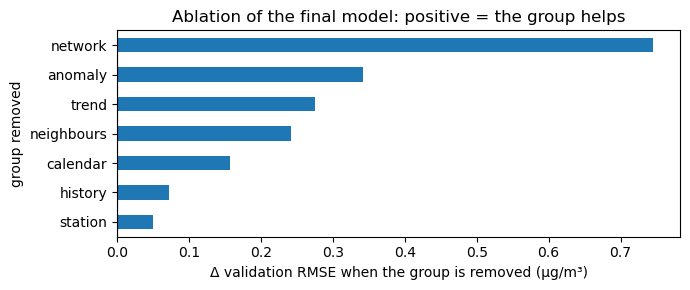

In [16]:
fig, ax = plt.subplots(figsize=(7, 3))
ablation["Δ RMSE vs final"].sort_values().plot.barh(ax=ax, color="tab:blue")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Δ validation RMSE when the group is removed (µg/m³)")
ax.set_title("Ablation of the final model: positive = the group helps")
plt.tight_layout(); plt.show()

### Part 2 questions
*(Numbers are rounded from the outputs above; the second decimal can shift slightly between scikit-learn
versions.)*

**Final model:** mean of ridge (alpha chosen on validation) and shallow boosted trees, both predicting the 24 h
change, on 6 groups / 37 features: `neighbours`, `network`, `history`, `trend`, `calendar`, `anomaly`.
Validation **RMSE ≈ 28.2, MAE ≈ 16.1**, against persistence 32.75 / 17.47 and Ridge-29 29.58 / 18.16. It wins on
both metrics in every month.

**What did each feature group add?** Greedy elimination removed `recent` (the 24 raw lags) and then `station`.
In the final-model ablation, every remaining group earns its place:
- **`network`** (≈ +0.6 RMSE when removed): the largest. PM2.5 episodes in Bihar are regional (shared weather),
  so the state-wide level and its PCA pattern predict tomorrow's local level.
- **`anomaly`** (≈ +0.3): how far the station sits above or below its surroundings. A local excess tends to fade
  by the next day. It was found by importance screening on training data (above), and the bootstrap shows its
  gain is real (the 95% interval for the difference lies entirely below zero).
- **`neighbours`**, **`calendar`**, **`trend`** (≈ +0.1 to +0.2 each) and **`history`** (≈ +0.1): smaller but positive.

**Where groups overlap:** `recent`, `history` and `trend` all come from the station's own past. With all of them
present, removing `recent` *improves* validation (24 collinear lags add variance, not information).
`station` was dropped once `anomaly` was in: both describe how a station differs from its surroundings, and the
anomaly features do it with current data rather than a fixed training mean. `trend` matters much less than it
did before `anomaly` existed (about +3.5 in the first version), because "now minus today's mean" and "now minus
the neighbours" carry related information. `neighbours` and `network` both summarise the spatial state, so each
looks small on its own.

**How new features were found:** 14 candidates were ranked by **permutation importance** on a held-out slice of
the *training* period (trees fitted on Jan–Jun, scored on Jul–Aug), so validation was not used to pick them.
`own_minus_nn` was far ahead of every other candidate. Its relatives were grouped, and since they are strongly
correlated, **PCA** compressed them to 2 components (≈ 95% of their variance).

**Ideas that did not help** (tables above):
- **PCA inside every group** (95% variance): worse (≈ 28.9 vs ≈ 28.5 with the same raw groups). PCA keeps the
  directions with the most *variance*, not the ones that predict tomorrow, so it discards small but useful
  differences. PCA helped only on the new anomaly group, whose 6 features are near-duplicates.
- **Tuning the ensemble weight**: the best validation weight and the weight learned inside the training period
  are both within about 0.05 of the 50/50 average, which is within noise, so 50/50 is kept.
- **Predicting log(1+y)** and transforming back: much worse (≈ 41). The back-transform gives roughly the median
  and badly under-forecasts the high November days that dominate RMSE.
- **Up-weighting winter (Jan–Feb) targets**: worse (≈ 29.4 vs ≈ 28.9); deep-winter dynamics differ from the autumn
  build-up. **kNN**: worse (≈ 29.6); in 72 dimensions, distances are dominated by weakly relevant features.
  **Lasso ≈ ridge**: the features are correlated and sparsity does not help.

**Did a more flexible model beat ridge?** Only when constrained. With the change target, the random forest
(≈ 28.7) beats ridge (≈ 28.9) and shallow boosted trees roughly tie with it. Deep boosted trees predicting the
**level** reach **≈ 17 train RMSE but ≈ 32 on validation**: much better on the training months and worse than ridge
on validation. That is overfitting plus distribution shift: trees memorise Jan–Aug patterns and, predicting
piecewise constants, cannot extrapolate to the higher November levels. The **average of ridge and shallow trees**
is best (≈ 28.2) because the two make partly independent errors.

**What information that we don't have would help most?** Meteorology: wind speed and direction, mixing-layer
height, temperature inversions and rain. Most of the error is station-specific scatter, and about 40% of squared
error comes from 10 November smog days that weather and crop burning drive. Also crop-residue fire counts
(Oct–Nov stubble burning) and an event calendar (Diwali on 31 Oct–1 Nov, Chhath in early November). External data
is not allowed here, but these would matter most.

### Final Part 2 results next to both baselines

In [17]:
P2 = pd.DataFrame([evaluate(P1_PRED["Persistence"], va24, name="Persistence"),
                   evaluate(P1_PRED["Ridge-29"], va24, name="Ridge-29 (Part 1)"),
                   evaluate(val_pred[FINAL], va24, name="Final model (Part 2)")])
P2

overall           Sep           Oct           Nov       
                        RMSE    MAE   RMSE    MAE   RMSE    MAE   RMSE    MAE
Persistence            32.75  17.47  23.33   8.91  20.22  11.97  47.81  31.70
Ridge-29 (Part 1)      29.58  18.16  20.34  10.35  19.36  13.46  43.06  30.81
Final model (Part 2)   28.20  16.10  19.56   8.46  17.67  11.22  41.31  28.78

In [18]:
# Save validation predictions in the shared team format (91 targets x 468 stations) for comparing versions
val_table = pd.DataFrame(val_pred[FINAL].reshape(len(va24), S), index=times[va24 + 24], columns=W.columns)
val_table.index.name = "target_time"
val_table.to_csv("val_pred_aaryan_final.csv", float_format="%.3f")
print("saved val_pred_aaryan_final.csv", val_table.shape)

saved val_pred_aaryan_final.csv (91, 468)


---
## Part 3: Lead time
The target stays at 12:00 on day d+1. The issue time moves closer: leads of 1, 3, 6, 12 and 24 h
(issue at 11:00, 09:00, 06:00, 00:00 on day d+1, and 12:00 on day d). For each lead:
1. **Persistence:** the reading at the issue time.
2. **Ridge-29:** the same 29 features taken relative to the new issue time, refitted for that lead.
3. **The Part 2 model:** same features, groups and hyperparameters, with the feature builder
   (station stats, PCA, k-means) and both members refitted for that lead.

The validation set is the same 91 noon targets for every lead.

In [19]:
LEADS = [1, 3, 6, 12, 24]
lead_rows, lead_val_pred = [], {}
for L in LEADS:
    tr_L, va_L = issue_rows(lead=L)
    # persistence
    p_pers = persistence(va_L)
    # ridge-29 refitted for this lead
    rm, _ = fit_ridge29(tr_L, lead=L)
    p_r29 = predict_ridge29(rm, va_L)
    # Part 2 model refitted for this lead
    tr_L2 = part2_rows(tr_L)
    fb_L = F.FeatureBuilder(stations, groups=SELECTED, seed=SEED, lead=L).fit(V[:TRAIN_STATS_END], tr_L2)
    Xtr_L, _ = fb_L.transform(V, tr_L2, times)
    Xva_L, _ = fb_L.transform(V, va_L, times)
    models_L = fit_final(Xtr_L, F.targets(V, tr_L2, L), V[tr_L2].reshape(-1))
    p_fin = predict_final(models_L, Xva_L, V[va_L].reshape(-1))
    lead_val_pred[L] = p_fin
    for name, p_ in [("Persistence", p_pers), ("Ridge-29", p_r29), ("Final model", p_fin)]:
        e = evaluate(p_, va_L, lead=L, name=name)
        lead_rows.append({"lead (h)": L, "issue time": times[va_L[0]].strftime("%H:%M"), "method": name,
                          "RMSE": e[("overall", "RMSE")], "MAE": e[("overall", "MAE")]})
    print(f"lead {L:2d} h done")
lead_tab = pd.DataFrame(lead_rows)
pd.concat({"RMSE": lead_tab.pivot(index="lead (h)", columns="method", values="RMSE"),
           "MAE": lead_tab.pivot(index="lead (h)", columns="method", values="MAE")}, axis=1).round(2)

c:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


lead  1 h done


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


lead  3 h done


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


lead  6 h done


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


lead 12 h done


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


lead 24 h done


RMSE                              MAE                     
method   Final model Persistence Ridge-29 Final model Persistence Ridge-29
lead (h)                                                                  
1              19.06       23.95    18.95        8.31       10.36     8.67
3              30.45       51.43    28.51       17.58       28.28    16.70
6              32.85       66.82    34.06       19.78       41.28    23.16
12             33.31       72.74    31.97       20.49       46.74    21.31
24             28.20       32.75    29.58       16.10       17.47    18.16

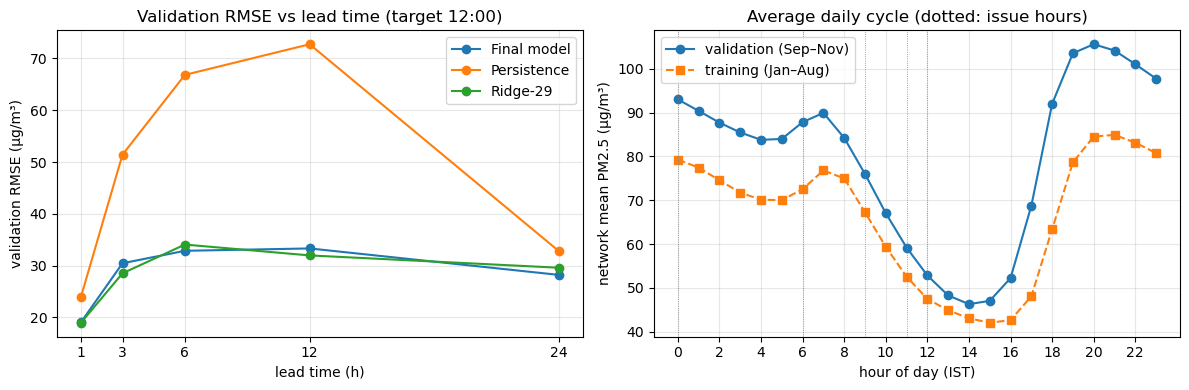

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, g in lead_tab.groupby("method"):
    ax[0].plot(g["lead (h)"], g.RMSE, "o-", label=name)
ax[0].set_xticks(LEADS); ax[0].set_xlabel("lead time (h)"); ax[0].set_ylabel("validation RMSE (µg/m³)")
ax[0].set_title("Validation RMSE vs lead time (target 12:00)"); ax[0].legend(); ax[0].grid(alpha=0.3)
# average PM2.5 by hour of day: explains the persistence curve
hod_val = W.loc[VAL_START:VAL_END].groupby(times[(times >= VAL_START) & (times <= VAL_END)].hour).mean().mean(1)
hod_tr = W.loc[:TRAIN_END].groupby(times[times <= TRAIN_END].hour).mean().mean(1)
ax[1].plot(hod_val.index, hod_val.values, "o-", label="validation (Sep–Nov)")
ax[1].plot(hod_tr.index, hod_tr.values, "s--", label="training (Jan–Aug)")
for L in LEADS:
    ax[1].axvline((12 - L) % 24, color="grey", lw=0.6, ls=":")
ax[1].set_xticks(range(0, 24, 2)); ax[1].set_xlabel("hour of day (IST)"); ax[1].set_ylabel("network mean PM2.5 (µg/m³)")
ax[1].set_title("Average daily cycle (dotted: issue hours)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [21]:
print("1-hour lead (nowcast), reported separately:")
print(lead_tab[lead_tab["lead (h)"] == 1].set_index("method")[["RMSE", "MAE"]].round(2).to_string())
print("\n24-hour lead (day-ahead, the main task):")
print(lead_tab[lead_tab["lead (h)"] == 24].set_index("method")[["RMSE", "MAE"]].round(2).to_string())

1-hour lead (nowcast), reported separately:
              RMSE    MAE
method                   
Persistence  23.95  10.36
Ridge-29     18.95   8.67
Final model  19.06   8.31

24-hour lead (day-ahead, the main task):
              RMSE    MAE
method                   
Persistence  32.75  17.47
Ridge-29     29.58  18.16
Final model  28.20  16.10


### Part 3 questions
**Persistence at 1 h, 24 h and in between:** yes, there is a big difference. Persistence is best at 1 h (≈ 24 RMSE),
much worse at 3–12 h (≈ 51–73), and then **dips back to ≈ 33 at 24 h**. The reason is the daily cycle (right plot):
noon sits near the daily *minimum* (≈ 53 µg/m³ in validation), while the night and early-morning readings at
the 00:00–09:00 issue hours are ≈ 76–93 µg/m³. Persistence issued at those hours carries the night level into
noon and over-forecasts. At 24 h, the issue and target are at the same hour of day, so the cycle cancels out.

**Do the learned models show the same behaviour?** Only partly. They learn the mapping from the issue-hour level
to the noon level, so most of the daily-cycle error disappears (≈ 28–34 RMSE at 3–12 h, against 51–73 for
persistence). But a mild version of the dip remains: they are worse at 6–12 h than at 24 h. The night-to-noon
relationship they learned on Jan–Aug does not transfer perfectly to Sep–Nov, where the night peak is
relatively larger (left vs right curves of the daily-cycle plot). The same-hour features available at the
24 h lead are not affected by that shift.

**Which lead time for a public warning service?** The **24 h (day-ahead, issued 12:00)** forecast. It gives people
a full day to plan, and it is *more accurate than issuing the same target at 00:00–09:00*. The cost compared to a
1-hour nowcast is about **9 µg/m³ RMSE** (28.2 vs 19.1 for our model) and about 8 µg/m³ MAE. A nowcast is more
accurate but leaves no time to act on it.

---
## Part 4: Forecast maps vs observed maps
Station values are interpolated to the 3,396-point 0.05° grid by **inverse-distance weighting** (power 2, all
stations, distances in km). The same interpolation is used for observed values and for forecasts, so map
differences come only from the forecasts.

In [22]:
gx, gy = F.to_km(grid.latitude, grid.longitude)
sx, sy = F.to_km(stations.latitude, stations.longitude)
Dg = np.hypot(gx[:, None] - sx[None, :], gy[:, None] - sy[None, :])
Wg = 1.0 / np.maximum(Dg, 1e-6) ** 2
Wg /= Wg.sum(1, keepdims=True)                      # (3396 grid points, 468 stations)


def idw(values):
    """values: (..., 468) station values -> (..., 3396) grid values."""
    return values @ Wg.T


obs_st = F.targets(V, va24).reshape(len(va24), S)                 # 91 days x 468
fc_st = val_pred[FINAL].reshape(len(va24), S)
pe_st = P1_PRED["Persistence"].reshape(len(va24), S)
obs_map, fc_map, pe_map = idw(obs_st), idw(fc_st), idw(pe_st)
days = times[va24 + 24]


def daily_scores(fmap, fst):
    map_rmse = np.sqrt(((fmap - obs_map) ** 2).mean(1))
    patt = np.array([np.corrcoef(fmap[k], obs_map[k])[0, 1] for k in range(len(days))])
    st_rmse = np.sqrt(((fst - obs_st) ** 2).mean(1))
    return pd.DataFrame({"map RMSE": map_rmse, "pattern corr": patt, "station RMSE": st_rmse}, index=days)


sc_fc, sc_pe = daily_scores(fc_map, fc_st), daily_scores(pe_map, pe_st)
summary4 = pd.DataFrame({"Persistence": sc_pe.mean(), "Final model": sc_fc.mean()}).T
summary4["station RMSE (pooled)"] = [rmse(pe_st.ravel(), obs_st.ravel()), rmse(fc_st.ravel(), obs_st.ravel())]
summary4.round(3)

,map RMSE,pattern corr,station RMSE,station RMSE (pooled)
Persistence,15.37,0.58,28.57,32.74
Final model,13.96,0.61,24.81,28.20


clean day                2024-09-15  observed station mean    7.9 µg/m³, our station RMSE 19.6
polluted day             2024-11-27  observed station mean  175.0 µg/m³, our station RMSE 63.9
worst day for our model  2024-11-29  observed station mean   76.6 µg/m³, our station RMSE 79.8


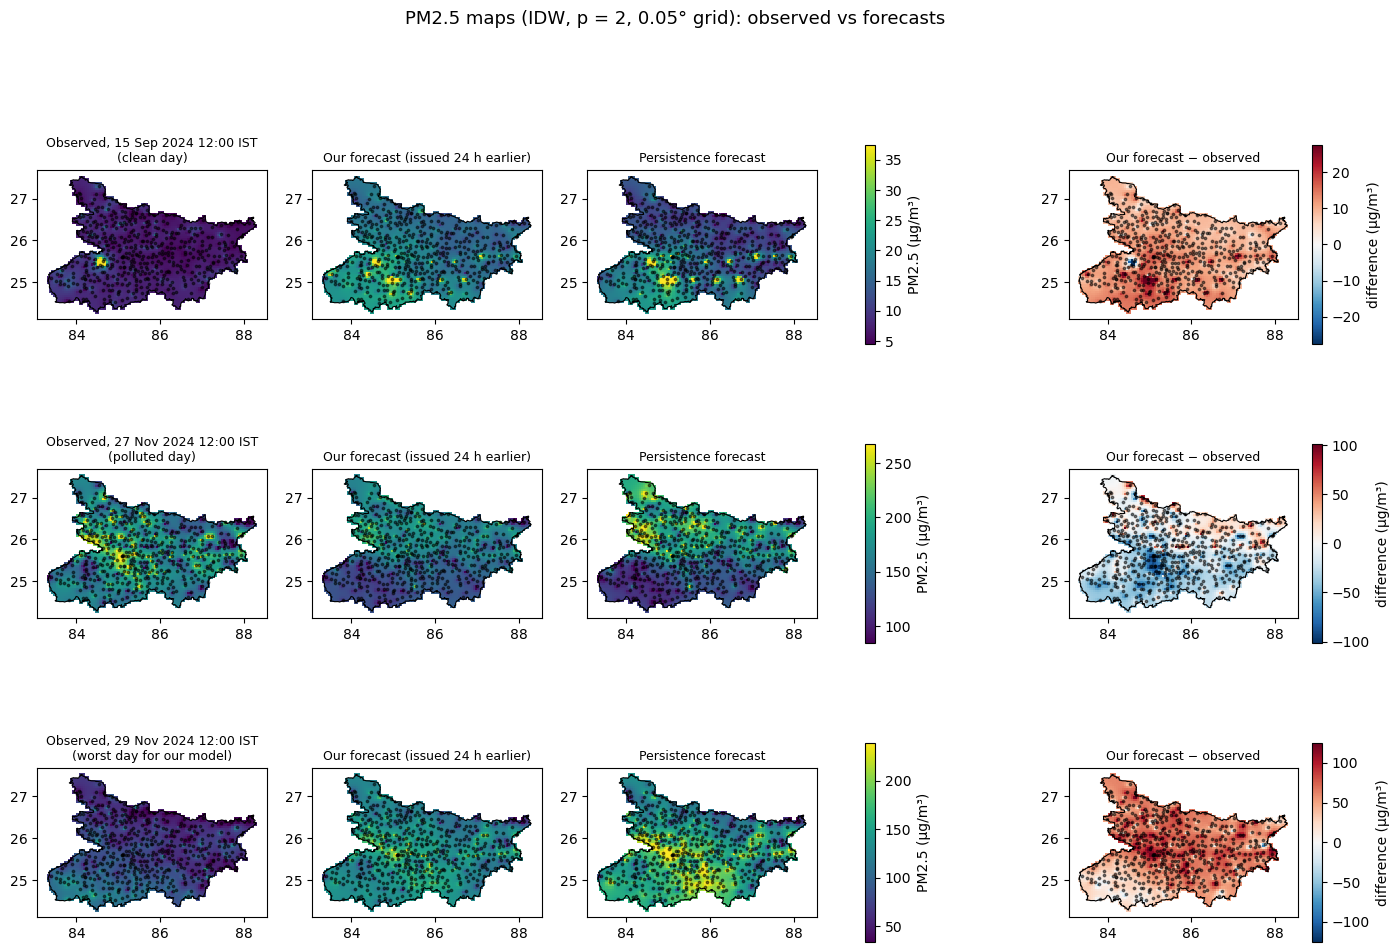

In [23]:
k_clean = int(np.argmin(obs_st.mean(1)))
k_poll = int(np.argmax(obs_st.mean(1)))
k_worst = int(np.argmax(sc_fc["station RMSE"].values))
chosen = {"clean day": k_clean, "polluted day": k_poll, "worst day for our model": k_worst}
for lab, k in chosen.items():
    print(f"{lab:24s} {days[k].date()}  observed station mean {obs_st[k].mean():6.1f} µg/m³, "
          f"our station RMSE {sc_fc['station RMSE'].iloc[k]:.1f}")


def draw(ax, z, title, vmin, vmax, cmap):
    sc = ax.scatter(grid.longitude, grid.latitude, c=z, s=9, marker="s", cmap=cmap, vmin=vmin, vmax=vmax,
                    linewidths=0)
    ax.plot(boundary.longitude, boundary.latitude, "k-", lw=0.8)
    ax.scatter(stations.longitude, stations.latitude, s=3, c="k", alpha=0.5)
    ax.set_title(title, fontsize=9); ax.set_aspect("equal"); ax.set_xticks([84, 86, 88]); ax.set_yticks([25, 26, 27])
    return sc


fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for r, (lab, k) in enumerate(chosen.items()):
    vmax = np.percentile(np.r_[obs_map[k], fc_map[k], pe_map[k]], 99)
    vmin = np.percentile(np.r_[obs_map[k], fc_map[k], pe_map[k]], 1)
    when = f"{days[k]:%d %b %Y} 12:00 IST"
    s1 = draw(axes[r, 0], obs_map[k], f"Observed, {when}\n({lab})", vmin, vmax, "viridis")
    draw(axes[r, 1], fc_map[k], f"Our forecast (issued 24 h earlier)", vmin, vmax, "viridis")
    draw(axes[r, 2], pe_map[k], f"Persistence forecast", vmin, vmax, "viridis")
    d = fc_map[k] - obs_map[k]
    lim = np.percentile(np.abs(d), 99)
    s2 = draw(axes[r, 3], d, "Our forecast − observed", -lim, lim, "RdBu_r")
    fig.colorbar(s1, ax=axes[r, :3], shrink=0.8, label="PM2.5 (µg/m³)")
    fig.colorbar(s2, ax=axes[r, 3], shrink=0.8, label="difference (µg/m³)")
fig.suptitle("PM2.5 maps (IDW, p = 2, 0.05° grid): observed vs forecasts", fontsize=13)
plt.show()

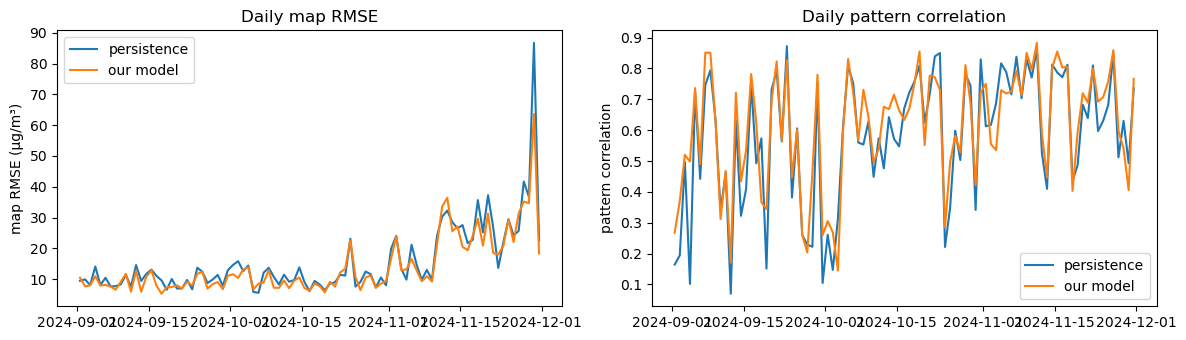

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(days, sc_pe["map RMSE"], label="persistence"); ax[0].plot(days, sc_fc["map RMSE"], label="our model")
ax[0].set_ylabel("map RMSE (µg/m³)"); ax[0].legend(); ax[0].set_title("Daily map RMSE")
ax[1].plot(days, sc_pe["pattern corr"], label="persistence"); ax[1].plot(days, sc_fc["pattern corr"], label="our model")
ax[1].set_ylabel("pattern correlation"); ax[1].legend(); ax[1].set_title("Daily pattern correlation")
plt.tight_layout(); plt.show()

### Part 4 questions
**Map RMSE vs station RMSE:** the **map RMSE is much lower** (≈ 14 vs ≈ 25 daily station RMSE for our model; the
same holds for persistence). IDW averages many stations into every grid cell, which smooths out station-level
errors and spikes in *both* maps, so they agree better than the stations do. The number to quote as forecast
accuracy is the **station RMSE**: it compares forecasts with actual measurements, while map RMSE compares two
interpolations and flatters the forecast.

**Why the observed map is not ground truth:** it is itself a model. IDW assumes PM2.5 varies smoothly between
stations, with no knowledge of sources, roads, towns or wind. It cannot show a hotspot that lies between
stations, and it is least reliable far from stations (edges, sparse areas). The station values are also from
low-cost sensors with noise, and some were gap-filled upstream from neighbours (not marked in the file). So the
"observed" map is a smoothed estimate whose error at any grid cell is unknown.

**Good pattern correlation but poor RMSE:** a forecast with the right spatial pattern (which districts are
dirtier or cleaner) but the wrong overall level. For example, a uniform over-forecast of +50 µg/m³ everywhere, or a
correct pattern with the contrast exaggerated. Correlation ignores such offsets and scalings; RMSE does not.
The worst day here (29 Nov) is this kind of case: the difference map is red almost everywhere, a near-uniform
over-forecast. For a **public warning**, the **level** matters more, because warnings are about crossing
thresholds (e.g. AQI categories). So RMSE/bias matters more than pattern correlation, though the pattern helps
target the worst areas.

---
## Part 5: Refit on all targets up to 30 Nov and save the submission model
Same features, groups and hyperparameters as the final Part 2 model. The feature builder statistics
(station means/std, PCA, k-means, anomaly scaling and PCA) are refitted on readings up to 30 Nov 12:00
(the last target), and both members are refitted on every 12:00 target from 10 Jan to 30 Nov.

**Version-independent model file.** A pickled scikit-learn model only loads reliably under the same
scikit-learn version that saved it, and the grader's version is unknown. So the fitted model is saved as
plain numpy arrays in `model.npz`: the feature-builder statistics, the PCA means and components, the k-means
labels, the ridge scaler and coefficients, and every boosted tree's split features, thresholds and leaf
values. `forecast.py` reads it with numpy alone and evaluates ridge and the trees itself. It computes
features only and never refits. The check below confirms it reproduces scikit-learn's predictions exactly.

In [25]:
tr_all = np.where(times.hour == 12)[0] - 24
tr_all = tr_all[(tr_all - LOOKBACK >= 0)]
ALL_STATS_END = np.searchsorted(times, pd.Timestamp("2024-11-30 12:00")) + 1
fb_all = F.FeatureBuilder(stations, groups=SELECTED, seed=SEED).fit(V[:ALL_STATS_END], tr_all)
X_all, _ = fb_all.transform(V, tr_all, times)
y_all, now_all = F.targets(V, tr_all), V[tr_all].reshape(-1)
ridge_all, hgb_all = fit_final(X_all, y_all, now_all)
F.export_model("model.npz", fb_all, ridge_all, hgb_all, list(W.columns), LOOKBACK)
print(f"final refit on {len(y_all)} rows ({len(tr_all)} targets {times[tr_all[0] + 24].date()} .. "
      f"{times[tr_all[-1] + 24].date()}); saved model.npz ({Path('model.npz').stat().st_size / 1e6:.2f} MB)")

c:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


final refit on 152568 rows (326 targets 2024-01-10 .. 2024-11-30); saved model.npz (0.14 MB)


In [26]:
# Check 1: the numpy-only model in model.npz reproduces scikit-learn's predictions on every training row
pm_check = F.PortableModel("model.npz")
p_sklearn = 0.5 * (ridge_all.predict(X_all) + hgb_all.predict(X_all))
X_np, _ = pm_check.builder.transform(V, tr_all, times)
print("max |difference| between model.npz and scikit-learn predictions:",
      float(np.abs(pm_check.predict_change(X_np) - p_sklearn).max()))

# Check 2: forecast.py (as the grader calls it) on a November issue time
import importlib
import forecast as fc_mod
importlib.reload(fc_mod)
t_issue = pd.Timestamp("2024-11-20 12:00")
s_pred = fc_mod.forecast(W.loc[:t_issue].copy(), t_issue)
k = int(np.where(tr_all == np.searchsorted(times, t_issue))[0][0])
direct = np.clip(p_sklearn.reshape(len(tr_all), S)[k] + V[tr_all[k]], 0, None)
print(type(s_pred).__name__, s_pred.shape, "finite:", bool(np.isfinite(s_pred).all()),
      "| max |forecast.py - notebook model|:", float(np.abs(s_pred.values - direct).max()))
print("Run the official checker from a terminal:\n"
      "  python <path to>/mp1-package/starter/check_submission.py <path to>/Aaryan_Code_Files")

max |difference| between model.npz and scikit-learn predictions: 0.0
Series (468,) finite: True | max |forecast.py - notebook model|: 0.0
Run the official checker from a terminal:
  python <path to>/mp1-package/starter/check_submission.py <path to>/Aaryan_Code_Files
